# Лабораторная работа 1. Иерархический кластерный анализ

*Студентка:* Барашкова Альбина Станиславовна <br>
*Цель:* Сегментировать потребителей леденцов на основе мотивов их потребления с помощью иерархического кластерного анализа для последующего формирования маркетинговых стратегий.<br>
*Гипотеза:* Потребительская аудитория неоднородна и разделяется на 3-4 устойчивых сегмента <br>

### импорт библиотек

In [2]:
import numpy as np
import pandas as pd

import matplotlib
import matplotlib.pyplot as plt
matplotlib.style.use('ggplot')
%matplotlib inline

In [3]:
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

### предобработка данных

In [4]:
df = pd.read_csv('Леденцы.dat', sep =';')

In [5]:
df.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
0,4,5,5,5,3,3,3,3,3,3,3
1,5,4,5,5,3,3,3,3,3,3,3
2,5,5,4,5,3,3,3,3,3,3,3
3,5,4,5,5,3,3,3,3,3,3,3
4,4,5,5,5,3,3,3,3,3,3,3


In [6]:
df.shape

(338, 11)

In [7]:
df = df.reset_index(drop = True)

Все признаки V1–V11 находятся на сопоставимых шкалах  (баллы от 1 до 5), и ни один из них не имеет существенно большего числового масштаба, чем остальные, поэтому стандартизация не нужна.<br>
Пропусков и выбросов нет <br>

In [8]:
df.describe()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
count,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000
mean,3.544379,3.526627,3.517751,3.411243,3.207101,3.204142,3.254438,3.289941,3.603550,3.550296,3.565089
std,0.955748,0.956410,0.990150,0.992311,0.867314,0.869725,0.844107,0.821784,0.969682,0.927082,0.942042
min,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000
25%,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000
50%,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000
75%,5.000000,5.000000,5.000000,4.000000,3.000000,3.000000,3.000000,3.000000,5.000000,5.000000,5.000000
max,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000


### построение дендрограммы и каменистой осыпи, выбор числа кластеров

In [9]:
link = linkage(df, 'ward', 'euclidean')

Мера сходства - евклидово расстояние. Евклидово расстояние это естественное геометрическое расстояние для числовых балльных оценок. <br>

Метод кластеризации - метод Уорда. Он минимизирует внутрикластерную дисперсию, что подходит для поиска компактных и плотных потребительских сегментов <br>


In [10]:
link

array([[  0.        ,   4.        ,   0.        ,   2.        ],
       [  1.        ,   3.        ,   0.        ,   2.        ],
       [  2.        ,   6.        ,   0.        ,   2.        ],
       ...,
       [664.        , 669.        ,  30.21829021, 120.        ],
       [667.        , 672.        ,  43.44161878, 230.        ],
       [671.        , 673.        ,  51.70554708, 338.        ]],
      shape=(337, 4))

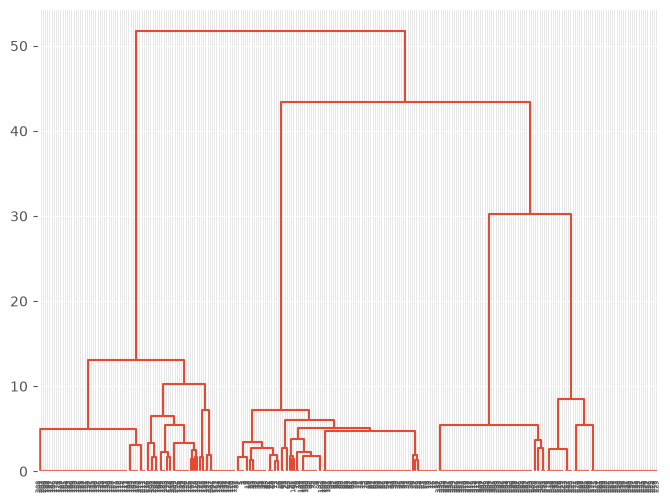

In [13]:
fig = plt.figure(figsize = (8, 6))
dn = dendrogram(link, color_threshold = -1, labels = df.index.tolist())

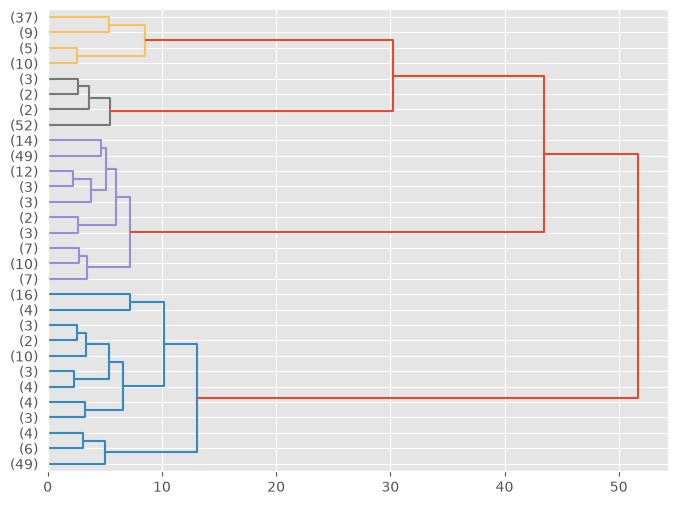

In [29]:
fig = plt.figure(figsize = (8, 6))
dn = dendrogram(link, 
                 color_threshold = 20, # порог/расстояние,на уровне 20 - 4 кластера
                truncate_mode='lastp', orientation = "right",
                leaf_rotation=0.,labels = df.index.tolist())

In [32]:
dist = link[:,2]

Text(0, 0.5, 'Расстояние')

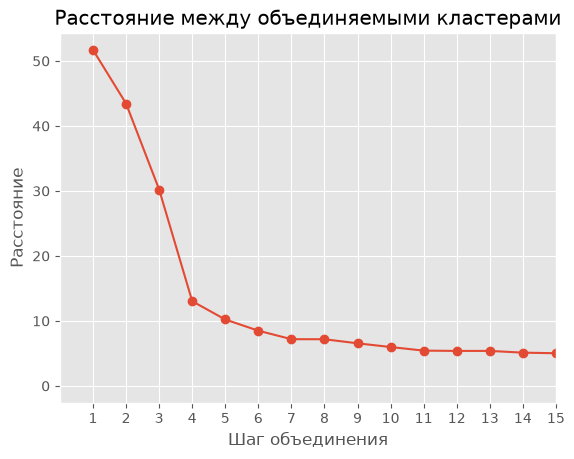

In [34]:
dist_rev= dist[::-1]
idxs = range(1, len(dist) + 1)
plt.plot(idxs, dist_rev, marker='o')
plt.xlim(0, 15) # обрезаем ось х
plt.xticks(range(1, 16)) # чтобы на оси х были цифры 1-15
plt.title('Расстояние между объединяемыми кластерами')
plt.xlabel('Шаг объединения') # по сути - кол-во кластеров
plt.ylabel('Расстояние') # расстояние между кластерами в момент объединения


Для определения оптимального числа кластеров использованы два метода: <br>

1) Дендрограмма. Демонстрирует деление на 4 независимые ветви при уровне расстояния среза на отрезке [13;30], срез выбран на уровне 20. <br>

2) Каменистая осыпь. Точка перегиба приходится на 4 кластера. При переходе от 4 к 3 кластерам происходит резкий скачок расстояния объединения (с 13 до 30), что говорит о вынужденном склеивании разнородных групп. Дробление на 5 и более групп снижает расстояние незначительно. <br>

Итог: Оптимальное число кластеров — 4<br>

In [30]:
df['cluster'] = fcluster(link, 4, criterion = 'maxclust')

In [35]:
df.groupby('cluster').size()

cluster
1    108
2    110
3     59
4     61
dtype: int64

Кластеры распределились в следующих пропорциях. Все сегменты являются устойчивыми и достаточно крупными (нет выбросов из единичных наблюдений) <br>


### профилирование кластеров

In [31]:
df.groupby('cluster').mean()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
cluster,,,,,,,,,,,
1,2.824074,2.833333,2.768519,2.620370,2.611111,2.583333,2.750000,2.916667,4.953704,4.814815,4.861111
2,4.845455,4.800000,4.836364,4.681818,3.036364,3.036364,3.000000,2.990909,3.072727,3.045455,3.045455
3,3.000000,2.966102,2.966102,2.915254,2.915254,2.949153,4.915254,4.915254,3.000000,3.000000,3.000000
4,3.000000,3.000000,3.000000,3.000000,4.852459,4.852459,3.000000,2.918033,2.754098,2.754098,2.754098


Итоговые выводы и описание сегментов: <br>

1 кластер (108 чел, 32%) - Медицинский (высокие баллы по шкалам 9-11) <br>
Интерпретация: Потребители покупают леденцы при простуде как лечебное средство <br>

2 кластер (110 чел, 32,5%) - Освежить дыхание + уверенность (высокие баллы по шкалам 1-4) <br>
Интерпретация: Потребители используют леденцы для для гигиены полости рта или после еды <br>

3 кластер (59 чел, 17,5%) - Для концентрации (высокие баллы по шкалам 7-8) <br>
Интерпретация: Потребеители воспринимают леденцы как способ фокусирования на делах и задачах. <br>

4 кластер (61 чел, 18%) - Сладкоежки (высокие баллы по шкалам 5-6) <br>
Интерперетация: Потребители заменяют леденцами другие кондитерские изделия <br>

### Бизнес вывод

Рынок леденцов четко разделен на два ключевых направления: массовое (около 65% потребителей) и нишевое (около 35%), что исключает возможность продвижения универсального продукта. <br>

Основной объем продаж и стабильную выручку компании обеспечивают два крупных сегмента - «Медицинский» (32%) и «Свежесть дыхания» (32,5%). 
Для первого приоритетны продажи через аптеки и высокая маржинальность за счет лечебных свойств, а для второго - покупки в прикассовых зонах супермаркетов как альтернатива жевательной резинке. <br>

Оставшуюся треть рынка формируют перспективные нишевые группы, готовые платить за специализированный продукт. Сегмент «Концентрации» (17,5%) открывает возможность выхода в категорию питания для офисных работников и студентов через леденцы с кофеином и витаминами. <br>
В то же время сегмент «Сладкоежек» (18%) выгодно развивать в рамках ЗОЖ тренда, предлагая низкокалорийные сладости без сахара. <br>

Таким образом, наиболее экономически эффективной для производителя является стратегия дифференциации: удержание доли рынка за счет классических освежающих и лечебных линеек с одновременным запуском продуктов для работы и здорового перекуса. <br>